## 🔧  **SETUP**

In [2]:
import os

#  Imposta il percorso della cartella condivisa (aggiorna il nome se diverso) ...
!ls "/kaggle/input/dataset/"
shared_folder = "/kaggle/input/dataset"

# Controlla se la cartella esiste e spostati al suo interno
if os.path.exists(shared_folder):
    os.chdir(shared_folder)
    print(f"✅ Cartella impostata correttamente:\n{os.getcwd()}")
else:
    print("❌ La cartella dataset non trovata.")


test_data  train_data  train_labels.csv
✅ Cartella impostata correttamente:
/kaggle/input/dataset


### ⚙️ **Libraries Import**

In [4]:
# Set seed for reproducibility
SEED = 100

# Import necessary libraries
import os

# Set environment variables before importing modules
os.environ['PYTHONHASHSEED'] = str(SEED)
os.environ['MPLCONFIGDIR'] = os.getcwd() + '/configs/'

# Suppress warnings
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.simplefilter(action='ignore', category=Warning)

# Import necessary modules
import logging
import random
import numpy as np
from pathlib import Path


# Set seeds for random number generators in NumPy and Python
np.random.seed(SEED)
random.seed(SEED)

# Import PyTorch
import torch
torch.manual_seed(SEED)
from torch import nn
from torchsummary import summary
from torch.utils.tensorboard import SummaryWriter
import torchvision
from torchvision.transforms import v2 as transforms
from torch.utils.data import TensorDataset, DataLoader
!pip install torchview
from torchview import draw_graph

# Configurazione di TensorBoard e directory
#logs_dir = "tensorboard"
#!pkill -f tensorboard
#%load_ext tensorboard
#!mkdir -p models

if torch.cuda.is_available():
    device = torch.device("cuda")
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True
else:
    device = torch.device("cpu")

print(f"PyTorch version: {torch.__version__}")
print(f"Device: {device}")

# Import other libraries
import cv2
import copy
import shutil
from itertools import product
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.model_selection import train_test_split
from PIL import Image
import matplotlib.gridspec as gridspec
import requests
from io import BytesIO

# Configure plot display settings
sns.set(font_scale=1.4)
sns.set_style('white')
plt.rc('font', size=14)
%matplotlib inline

PyTorch version: 2.6.0+cu124
Device: cpu


### ⏳ **Data Loading**

In [ ]:
def load_medical_dataset(folder, target_size=(224, 224)):
    """
    Load images and corresponding masks from a folder.
    
    Args:
        folder (str): Path to folder containing img_NNNN.png and mask_NNNN.png files
        target_size (tuple): Target image size (height, width)
    
    Returns:
        tuple: (images, masks) - both numpy arrays of shape (N, H, W, C)
    """
    images = []
    masks = []
    
    # Find all image files
    img_files = sorted([f for f in os.listdir(folder) if f.startswith('img_') and f.endswith('.png')])
    
    print(f"Found {len(img_files)} images in {folder}")
    
    for img_file in img_files:
        # Construct corresponding mask filename
        mask_file = img_file.replace('img_', 'mask_')
        
        img_path = os.path.join(folder, img_file)
        mask_path = os.path.join(folder, mask_file)
        
        # Check if both image and mask exist
        if not os.path.exists(mask_path):
            print(f"Warning: Mask not found for {img_file}, skipping...")
            continue
        
        # Load image (in color)
        img = cv2.imread(img_path)
        if img is None:
            print(f"Warning: Could not load image {img_file}, skipping...")
            continue
        
        # Load mask (in grayscale - it's binary anyway)
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
        if mask is None:
            print(f"Warning: Could not load mask {mask_file}, skipping...")
            continue
        
        # Preprocess image
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = img / 255.0
        
        # Pad to square (no loss of data)
        h, w = img.shape[:2]
        dim = max(h, w)  # Use the larger dimension
        
        # Calculate padding needed
        pad_h = (dim - h) // 2
        pad_w = (dim - w) // 2
        
        # Pad image to square with white padding
        img = np.pad(img, ((pad_h, dim - h - pad_h), (pad_w, dim - w - pad_w), (0, 0)), mode='constant', constant_values=255)
        
        # Pad mask with black (0) - masks stay black at edges
        mask = np.pad(mask, ((pad_h, dim - h - pad_h), (pad_w, dim - w - pad_w)), mode='constant', constant_values=0)
        
        # Resize both to target size
        img = cv2.resize(img, target_size)
        mask = cv2.resize(mask, target_size, interpolation=cv2.INTER_NEAREST)
        
        # Normalize mask to [0, 1]
        mask = mask / 255.0
        
        # Add channel dimension to mask (to match image format)
        mask = np.expand_dims(mask, axis=-1)
        
        images.append(img)
        masks.append(mask)
    
    print(f"Successfully loaded {len(images)} image-mask pairs")
    
    return np.array(images), np.array(masks)


# Load training data
train_path = './train_data'
train_images, train_masks = load_medical_dataset(train_path)

print(f"\nTrain images shape: {train_images.shape}")  # (N, 224, 224, 3)
print(f"Train masks shape: {train_masks.shape}")      # (N, 224, 224, 1)

# Load test data
test_path = './test_data'
test_images, test_masks = load_medical_dataset(test_path)

print(f"\nTest images shape: {test_images.shape}")
print(f"Test masks shape: {test_masks.shape}")

In [ ]:
# Dopo che il caricamento è finito, salva i dati

# Crea la cartella di output se non esiste
output_folder = '/kaggle/working/'
os.makedirs(output_folder, exist_ok=True)

# Salva i dati come file .npy (formato binario compresso)
print("Saving train images...")
np.save(f'{output_folder}train_images.npy', train_images)

print("Saving train masks...")
np.save(f'{output_folder}train_masks.npy', train_masks)

print("Saving test images...")
np.save(f'{output_folder}test_images.npy', test_images)

print("Saving test masks...")
np.save(f'{output_folder}test_masks.npy', test_masks)

print("\nDataset salvato in /kaggle/working/")
print(f"Train images: {train_images.shape}")
print(f"Train masks: {train_masks.shape}")
print(f"Test images: {test_images.shape}")
print(f"Test masks: {test_masks.shape}")



In [5]:
# I numpy sono nel dataset ora (MESSI SUCCESSIVAMENTE)
train_images = np.load('/kaggle/input/datasetnumpy/train_images.npy')
train_masks = np.load('/kaggle/input/datasetnumpy/train_masks.npy')
test_images = np.load('/kaggle/input/datasetnumpy/test_images.npy')
test_masks = np.load('/kaggle/input/datasetnumpy/test_masks.npy')

print("Dati caricati dal dataset!")
print(f"Train images shape: {train_images.shape}")
print(f"Train masks shape: {train_masks.shape}")

Dati caricati dal dataset!
Train images shape: (1412, 224, 224, 3)
Train masks shape: (1412, 224, 224, 1)


### DATA VISUALIZATION

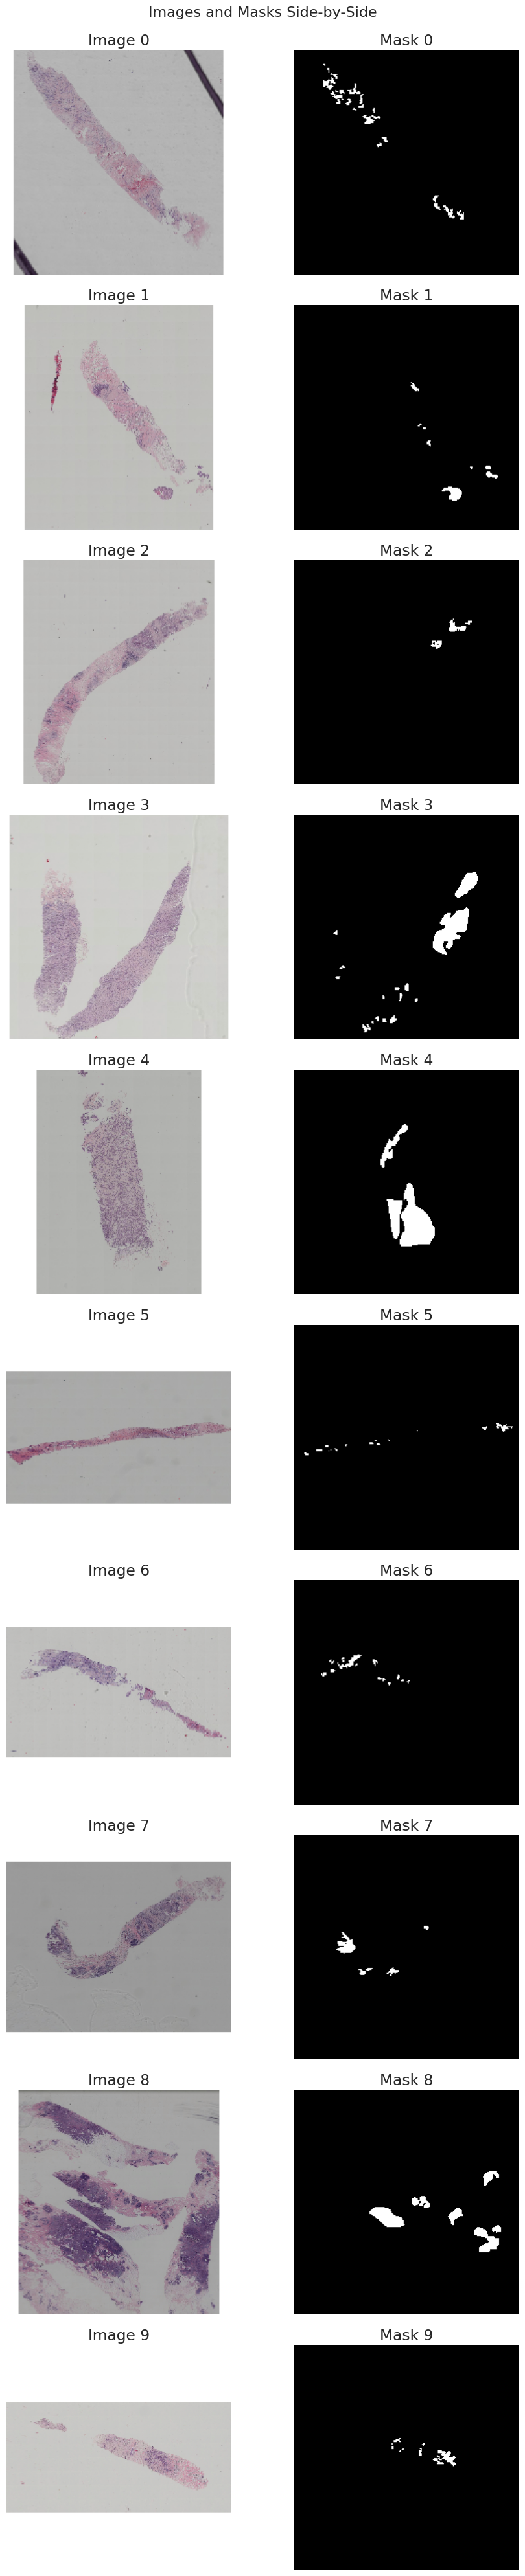

In [7]:

# Number of images to display
num_img = 10

# Display side-by-side comparison (image + mask)
fig, axes = plt.subplots(num_img, 2, figsize=(10, 4*num_img))
fig.suptitle('Images and Masks Side-by-Side', fontsize=16, y=0.995)

for i in range(num_img):
    # Image on left
    axes[i, 0].imshow(np.clip(train_images[i], 0, 1))
    axes[i, 0].set_title(f'Image {i}')
    axes[i, 0].axis('off')
    
    # Mask on right
    axes[i, 1].imshow(train_masks[i].squeeze(), cmap='gray')
    axes[i, 1].set_title(f'Mask {i}')
    axes[i, 1].axis('off')

plt.tight_layout()
plt.show()